# **Extra: Benchmark of the Collaborative Filtering Models on a Common Split**

The KNN and NMF labs evaluate on the 3/4/5 rating file, while the neural-network lab uses a different file with
2/3 ratings, scaled to 0-1. Their RMSEs are therefore not directly comparable.

This notebook trains every collaborative-filtering model from the labs on **one identical 70/30 split of each rating
file** and reports RMSE (and MAE) **in rating units**, so the comparison slide of the final presentation is fair:

| Model | Library | Settings (best from the labs) |
|---|---|---|
| Global-mean baseline | numpy | predicts the mean training rating |
| KNN (item-based) | Surprise `KNNBasic` | best similarity / k from the KNN lab |
| NMF | Surprise `NMF` | best n_factors / n_epochs from the NMF lab |
| SVD (extra) | Surprise `SVD` | default biased matrix factorisation |
| RecommenderNet | TensorFlow | the lab's network, 16-d embeddings |
| RecommenderNetV2 | TensorFlow | per-example dot product + dense head (NN lab, optional task) |
| Ridge on embeddings | scikit-learn | user + item embedding features (regression lab) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from surprise import Dataset, Reader, KNNBasic, NMF, SVD

rs = 123
datasets = {
    'ratings.csv (3/4/5)': pd.read_csv("../datasets/ratings.csv"),
    'ratings lab 05 (2/3)': pd.read_csv("../datasets/ratings (m03 lab 05).csv"),
}
for name, df in datasets.items():
    print(name, df.shape, df['rating'].value_counts().sort_index().to_dict())

ratings.csv (3/4/5) (233306, 3) {3: 77866, 4: 77936, 5: 77504}
ratings lab 05 (2/3) (233306, 3) {2.0: 10976, 3.0: 222330}


Best hyper-parameters found in the KNN and NMF labs:

In [2]:
knn_sweep = pd.read_csv('../results/knn_sweep.csv')
nmf_sweep = pd.read_csv('../results/nmf_sweep.csv')
best_knn = knn_sweep.loc[knn_sweep['rmse'].idxmin()]
best_nmf = nmf_sweep.loc[nmf_sweep['rmse'].idxmin()]
print(f"KNN: similarity={best_knn['similarity']}, k={int(best_knn['k'])}")
print(f"NMF: n_factors={int(best_nmf['n_factors'])}, n_epochs={int(best_nmf['n_epochs'])}, init=({best_nmf['init_low']}, {best_nmf['init_high']})")

KNN: similarity=cosine, k=40
NMF: n_factors=16, n_epochs=20, init=(0.0, 1.0)


### The two neural networks (same definitions as in the neural-network lab)

In [3]:
class RecommenderNet(keras.Model):
    def __init__(self, num_users, num_items, embedding_size=16, **kwargs):
        super().__init__(**kwargs)
        self.user_embedding_layer = layers.Embedding(num_users, embedding_size, name='user_embedding_layer',
                                                     embeddings_initializer='he_normal', embeddings_regularizer=keras.regularizers.l2(1e-6))
        self.user_bias = layers.Embedding(num_users, 1, name='user_bias')
        self.item_embedding_layer = layers.Embedding(num_items, embedding_size, name='item_embedding_layer',
                                                     embeddings_initializer='he_normal', embeddings_regularizer=keras.regularizers.l2(1e-6))
        self.item_bias = layers.Embedding(num_items, 1, name='item_bias')

    def call(self, inputs):
        user_vector = self.user_embedding_layer(inputs[:, 0])
        user_bias = self.user_bias(inputs[:, 0])
        item_vector = self.item_embedding_layer(inputs[:, 1])
        item_bias = self.item_bias(inputs[:, 1])
        dot_user_item = tf.tensordot(user_vector, item_vector, 2)
        return tf.nn.relu(dot_user_item + user_bias + item_bias)


class RecommenderNetV2(keras.Model):
    def __init__(self, num_users, num_items, embedding_size=32, **kwargs):
        super().__init__(**kwargs)
        regularizer = keras.regularizers.l2(1e-6)
        self.user_embedding_layer = layers.Embedding(num_users, embedding_size, embeddings_initializer='he_normal', embeddings_regularizer=regularizer)
        self.user_bias = layers.Embedding(num_users, 1)
        self.item_embedding_layer = layers.Embedding(num_items, embedding_size, embeddings_initializer='he_normal', embeddings_regularizer=regularizer)
        self.item_bias = layers.Embedding(num_items, 1)
        self.hidden = layers.Dense(64, activation='relu')
        self.dropout = layers.Dropout(0.2)
        self.out = layers.Dense(1)

    def call(self, inputs, training=False):
        user_vector = self.user_embedding_layer(inputs[:, 0])
        item_vector = self.item_embedding_layer(inputs[:, 1])
        dot_user_item = tf.reduce_sum(user_vector * item_vector, axis=1, keepdims=True)
        x = tf.concat([user_vector * item_vector, dot_user_item], axis=1)
        x = self.dropout(self.hidden(x), training=training)
        return tf.nn.sigmoid(self.out(x) + self.user_bias(inputs[:, 0]) + self.item_bias(inputs[:, 1]))

### Train and evaluate every model on the same split

In [4]:
user_emb = pd.read_csv("../datasets/user_embeddings.csv")
item_emb = pd.read_csv("../datasets/course_embeddings.csv")


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def surprise_predict(algo, train_df, test_df, scale):
    trainset = Dataset.load_from_df(train_df[['user', 'item', 'rating']], Reader(rating_scale=scale)).build_full_trainset()
    algo.fit(trainset)
    return np.array([algo.predict(u, i).est for u, i in zip(test_df['user'], test_df['item'])])


def nn_predict(model_class, train_df, test_df, all_df, lo, hi, embedding_size):
    user_idx = {u: i for i, u in enumerate(all_df['user'].unique())}
    item_idx = {c: i for i, c in enumerate(all_df['item'].unique())}
    encode = lambda d: np.stack([d['user'].map(user_idx).values, d['item'].map(item_idx).values], axis=1)
    x_all, y_all = encode(train_df), ((train_df['rating'] - lo) / (hi - lo)).values
    x_tr, x_val, y_tr, y_val = train_test_split(x_all, y_all, test_size=0.1, random_state=rs)
    tf.keras.utils.set_random_seed(rs)
    model = model_class(len(user_idx), len(item_idx), embedding_size)
    model.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=0.001))
    model.fit(x_tr, y_tr, batch_size=64, epochs=10, validation_data=(x_val, y_val), verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)])
    return model.predict(encode(test_df), batch_size=4096, verbose=0).ravel() * (hi - lo) + lo


def ridge_predict(train_df, test_df):
    def features(d):
        merged = d.merge(user_emb, on='user', how='left').merge(item_emb, on='item', how='left').fillna(0)
        return merged[[f'UFeature{i}' for i in range(16)]].values + merged[[f'CFeature{i}' for i in range(16)]].values
    model = Ridge(alpha=1.0).fit(features(train_df), train_df['rating'])
    return model.predict(features(test_df))


results = []
for data_name, df in datasets.items():
    lo, hi = df['rating'].min(), df['rating'].max()
    train_df, test_df = train_test_split(df, test_size=0.3, random_state=rs)
    y_test = test_df['rating'].values
    predictions = {
        'Global-mean baseline': np.full(len(test_df), train_df['rating'].mean()),
        f"KNN item-based ({best_knn['similarity']}, k={int(best_knn['k'])})": surprise_predict(
            KNNBasic(k=int(best_knn['k']), sim_options={'name': best_knn['similarity'], 'user_based': False}, verbose=False), train_df, test_df, (lo, hi)),
        f"NMF ({int(best_nmf['n_factors'])} factors)": surprise_predict(
            NMF(n_factors=int(best_nmf['n_factors']), n_epochs=int(best_nmf['n_epochs']), init_low=best_nmf['init_low'], init_high=best_nmf['init_high'], random_state=rs), train_df, test_df, (lo, hi)),
        'SVD': surprise_predict(SVD(random_state=rs), train_df, test_df, (lo, hi)),
        'RecommenderNet (lab)': nn_predict(RecommenderNet, train_df, test_df, df, lo, hi, 16),
        'RecommenderNetV2': nn_predict(RecommenderNetV2, train_df, test_df, df, lo, hi, 32),
        'Ridge on embeddings': ridge_predict(train_df, test_df),
    }
    for model_name, y_pred in predictions.items():
        y_pred = np.clip(y_pred, lo, hi)
        results.append({'dataset': data_name, 'model': model_name, 'rmse': rmse(y_test, y_pred), 'mae': mae(y_test, y_pred)})
        print(f"{data_name:24s} {model_name:32s} RMSE={results[-1]['rmse']:.4f}")

benchmark = pd.DataFrame(results)
benchmark.pivot(index='model', columns='dataset', values='rmse').round(4)

ratings.csv (3/4/5)      Global-mean baseline             RMSE=0.8138
ratings.csv (3/4/5)      KNN item-based (cosine, k=40)    RMSE=0.8918
ratings.csv (3/4/5)      NMF (16 factors)                 RMSE=0.9453
ratings.csv (3/4/5)      SVD                              RMSE=0.8390
ratings.csv (3/4/5)      RecommenderNet (lab)             RMSE=1.2888
ratings.csv (3/4/5)      RecommenderNetV2                 RMSE=0.8143
ratings.csv (3/4/5)      Ridge on embeddings              RMSE=0.8138


ratings lab 05 (2/3)     Global-mean baseline             RMSE=0.2104
ratings lab 05 (2/3)     KNN item-based (cosine, k=40)    RMSE=0.1929
ratings lab 05 (2/3)     NMF (16 factors)                 RMSE=0.1944
ratings lab 05 (2/3)     SVD                              RMSE=0.2647
ratings lab 05 (2/3)     RecommenderNet (lab)             RMSE=0.1517
ratings lab 05 (2/3)     RecommenderNetV2                 RMSE=0.1048
ratings lab 05 (2/3)     Ridge on embeddings              RMSE=0.2096


dataset,ratings lab 05 (2/3),ratings.csv (3/4/5)
model,,
Global-mean baseline,0.2104,0.8138
"KNN item-based (cosine, k=40)",0.1929,0.8918
NMF (16 factors),0.1944,0.9453
RecommenderNet (lab),0.1517,1.2888
RecommenderNetV2,0.1048,0.8143
Ridge on embeddings,0.2096,0.8138
SVD,0.2647,0.8390


### RMSE by model

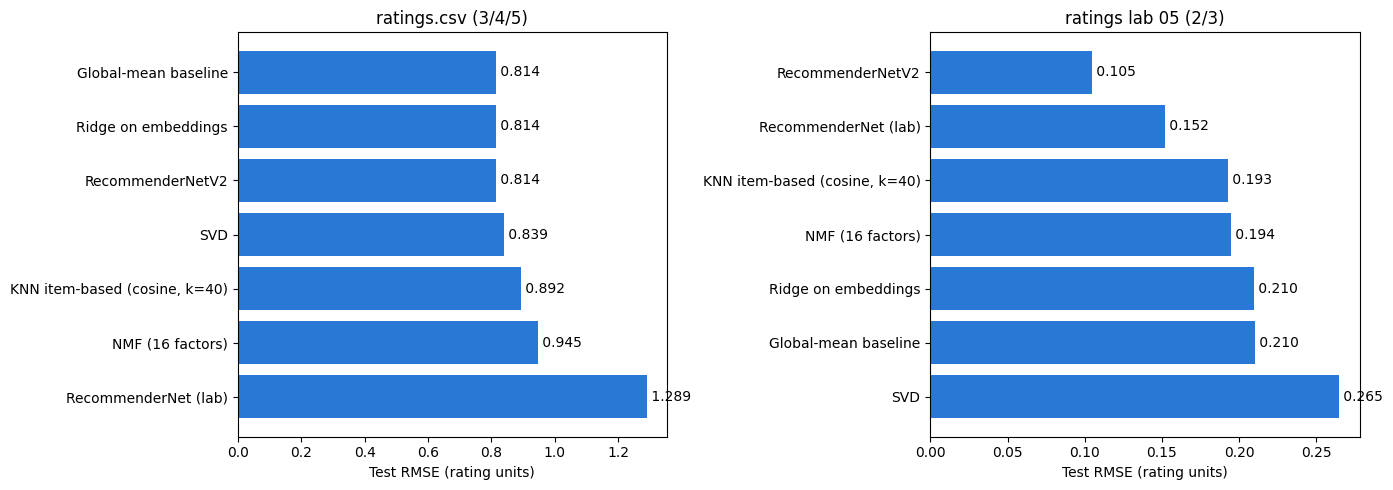

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (data_name, part) in zip(axes, benchmark.groupby('dataset', sort=False)):
    part = part.sort_values('rmse')
    ax.barh(part['model'], part['rmse'], color='#2a78d6')
    ax.invert_yaxis()
    ax.set_title(data_name)
    ax.set_xlabel('Test RMSE (rating units)')
    for y, v in enumerate(part['rmse']):
        ax.text(v, y, f' {v:.3f}', va='center')
plt.tight_layout()
plt.show()

In [6]:
import os
os.makedirs('../results', exist_ok=True)
benchmark.to_csv('../results/cf_benchmark.csv', index=False)

### Observations

* **Lab-05 file (2/3 ratings, real signal):** RecommenderNetV2 has the lowest RMSE (0.1048, 50% below the global-mean
  baseline of 0.2104), followed by the lab's RecommenderNet (0.1517). Item-based KNN (0.1929) and NMF (0.1944) improve
  on the baseline by about 8%. SVD with its default 100 factors overfits the sparse data (0.2647), and Ridge on the
  provided embeddings only matches the baseline.
* **ratings.csv (3/4/5 ratings):** the file has the same 233,306 (user, course) pairs as the lab-05 file, but its ratings
  are evenly spread over 3, 4 and 5 and uncorrelated with the lab-05 ratings. The global mean (0.8138) is therefore the
  best achievable RMSE: Ridge and RecommenderNetV2 match it, while models that fit noise (KNN, NMF, SVD and the lab's
  RecommenderNet) score worse.
* Conclusion: where the ratings carry signal, learned embeddings give the most accurate predictions; on random ratings no
  model can - or does - beat the baseline, which is why every model should be compared against one.